FastText CC is the model of choice since its trained on generelized data instead of only tweets it got  articales blogs social media etc...


In [122]:
from pathlib import Path
import pandas as pd

# 1. Chargement des données nettoyées
DATA_DIR = Path(r"c:\Users\user\Projets_Ghoufrane\LLMS\Decetction-Persuation\data")
df_train = pd.read_json(DATA_DIR / "task1B_train_cleaned_augmented.jsonl", lines=True, encoding="utf-8")
df_val   = pd.read_json(DATA_DIR / "task1B_dev_cleaned.jsonl", lines=True, encoding="utf-8")
df_test  = pd.read_json(DATA_DIR / "task1B_test_cleaned.jsonl", lines=True, encoding="utf-8")


In [123]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

Using device: cuda (NVIDIA GeForce GTX 1660 Ti)


In [124]:
def compute_vocab_oov(train_texts, val_texts, test_texts):
    """
    Calcule la différence de vocabulaire (OOV) entre Train et Val, et entre Train et Test.
    """
    # Extraction des vocabulaires uniques
    vocab_train = set(w for text in train_texts if isinstance(text, str) for w in text.split())
    vocab_val   = set(w for text in val_texts if isinstance(text, str) for w in text.split())
    vocab_test  = set(w for text in test_texts if isinstance(text, str) for w in text.split())

    # Mots présents dans Val / Test mais absents du Train
    diff_val  = vocab_val - vocab_train
    diff_test = vocab_test - vocab_train

    return {
        "Train vs Val": {
            "total_vocab_val": len(vocab_val),
            "oov_count": len(diff_val),
            "oov_rate_%": round((len(diff_val) / len(vocab_val)) * 100, 2) if vocab_val else 0.0,
            "oov_words": diff_val
        },
        "Train vs Test": {
            "total_vocab_test": len(vocab_test),
            "oov_count": len(diff_test),
            "oov_rate_%": round((len(diff_test) / len(vocab_test)) * 100, 2) if vocab_test else 0.0,
            "oov_words": diff_test
        }
    }

In [125]:
results = compute_vocab_oov(df_train["text"], df_val["text"], df_test["text"])

# Affichage des résultats
print(f"OOV Train vs Val  : {results['Train vs Val']['oov_count']} mots ({results['Train vs Val']['oov_rate_%']}%)")
print(f"OOV Train vs Test : {results['Train vs Test']['oov_count']} mots ({results['Train vs Test']['oov_rate_%']}%)")

OOV Train vs Val  : 1677 mots (35.82%)
OOV Train vs Test : 3154 mots (43.55%)


# Tokenize BASIC

FastText constate que le mot exact n'est pas dans son dictionnaire.
Il découpe immédiatement ce mot inconnu en sous-mots : '<سي', 'سيك', 'يكت', 'كتب', 'تبو', 'بون', 'ون>'...
Il retrouve les vecteurs de ces fragments (qu'il connaît déjà grâce à d'autres mots comme سيارة, يكتب, يلعبون, etc.).
Il fait simplement la somme (ou la moyenne) des vecteurs de ses fragments
v
mot_inconnu
	​

=
g∈subwords
∑
	​

v
g
	​


Le vecteur ainsi créé n'est pas aléatoire : il hérite du sens sémantique de sa racine (كتب) et de ses préfixes/suffixes (سيـ, ـون).

In [126]:
def tokenize(text: str) -> list[str]:
    """Découpage basique sur les espaces pour texte déjà nettoyé."""
    return text.split() if isinstance(text, str) else []

In [127]:
for name, df in [("Train", df_train), ("Validation", df_val), ("Test", df_test)]:
    # Ajout de la liste des tokens
    df["tokens"] = df["text"].apply(tokenize)
    # Ajout du nombre de mots par texte
    df["token_count"] = df["tokens"].apply(len)
    print(f"✅ {name:10} tokenisé ({len(df):,} exemples | {df['token_count'].sum():,} tokens au total)")
# 4. Aperçu du résultat sur le Train
print("\n--- Exemple de texte tokenisé (Train) ---")
display(df_train[["text", "tokens", "token_count"]].head(3))

✅ Train      tokenisé (2,535 exemples | 71,335 tokens au total)
✅ Validation tokenisé (259 exemples | 8,164 tokens au total)
✅ Test       tokenisé (503 exemples | 14,751 tokens au total)

--- Exemple de texte tokenisé (Train) ---


,text,tokens,token_count
0,جوجل يحتفل بعيد استقلال المملكة الأردنية الهاش...,"[جوجل, يحتفل, بعيد, استقلال, المملكة, الأردنية...",11
1,عاجل الأمن العراقي الهجوم تسبب باستشهاد آمر ال...,"[عاجل, الأمن, العراقي, الهجوم, تسبب, باستشهاد,...",19
2,وبحسب المنظمة الحقوقية الدولية، فقد دعت النياب...,"[وبحسب, المنظمة, الحقوقية, الدولية،, فقد, دعت,...",29


# charger le model

In [128]:
from huggingface_hub import hf_hub_download
import fasttext

model = fasttext.load_model(
    hf_hub_download("facebook/fasttext-ar-vectors", "model.bin")
)   

In [129]:
# 1. Vocabulaire unique du Train
vocab_train = set(w for text in df_train["text"] for w in text.split())

# 2. Vocabulaire du modèle officiel FastText
vocab_model = set(model.get_words())

# 3. Mots du Train absents du dictionnaire du modèle (OOV)
oov_train = vocab_train - vocab_model

# 4. Statistiques
oov_count = len(oov_train)
oov_rate = (oov_count / len(vocab_train)) * 100 if vocab_train else 0.0

print(f"Taille vocabulaire Train   : {len(vocab_train):,} mots")
print(f"Mots OOV (hors modèle)     : {oov_count:,} mots ({oov_rate:.2f}%)")
print(f"Couverture du modèle       : {100 - oov_rate:.2f}%")

Taille vocabulaire Train   : 22,414 mots
Mots OOV (hors modèle)     : 2,424 mots (10.81%)
Couverture du modèle       : 89.19%


In [130]:
# 1. Votre fonction tokenize (déjà présente dans votre notebook) :
# def tokenize(text: str) -> list[str]:
#     return text.split() if isinstance(text, str) else []

# 2. Application sur l'ensemble des splits : Train, Val et Test
splits = {
    "Train": df_train,
    "Val": df_val,
}

for name, df in splits.items():
    # A. Liste des tokens (mots découpés)
    df["tokens"] = df["text"].apply(tokenize)
    
    # C. Nombre de tokens par texte
    df["token_count"] = df["tokens"].apply(len)
    
    print(f"✅ {name:5} : {len(df):,} exemples | {df['token_count'].sum():,} tokens")

# 3. Aperçu rapide
display(df_train[["text", "tokens", "token_count"]].head(2))

✅ Train : 2,535 exemples | 71,335 tokens
✅ Val   : 259 exemples | 8,164 tokens


,text,tokens,token_count
0,جوجل يحتفل بعيد استقلال المملكة الأردنية الهاش...,"[جوجل, يحتفل, بعيد, استقلال, المملكة, الأردنية...",11
1,عاجل الأمن العراقي الهجوم تسبب باستشهاد آمر ال...,"[عاجل, الأمن, العراقي, الهجوم, تسبب, باستشهاد,...",19


# Embed_data

    Transforme une liste de textes tokenisés en représentations vectorielles FastText.

    Paramètres à ajuster (Tweaks) :
    --------------------------------
    :param tokenized_texts: Liste de listes de tokens (ex: df["tokens"].tolist()).
    :param model: Modèle FastText chargé (ex: model = fasttext.load_model(...)).
    :param mode: Type de sortie :
        - 'sequence' : Tenseur 3D (N, max_len, dim) pour BiLSTM, CNN, Transformer.
        - 'mean'     : Matrice 2D (N, dim) - moyenne des mots de la phrase.
        - 'max'      : Matrice 2D (N, dim) - maximum dimension par dimension.
        - 'mean_max' : Matrice 2D (N, dim * 2) - concaténation moyenne + max pooling.
    :param max_len: Longueur fixe des séquences (utilisé uniquement en mode 'sequence').
    :param padding: 'post' (zéros ajoutés à la fin) ou 'pre' (zéros ajoutés au début).
    :param truncating: 'post' (tronque les mots de la fin) ou 'pre' (tronque le début).
    :param use_subwords: 
        - True  : FastText calcule un vecteur pour TOUS les mots via ses sous-mots.
        - False : N'utilise que les mots du dictionnaire exact ; les autres deviennent UNK.
    :param unk_strategy: 'mean' (vecteur moyen neutre), 'random' ou 'zeros'.
    :param show_progress: Affiche la barre tqdm.

    :return: np.ndarray (2D ou 3D selon le mode).

Mean Pooling : effectue la moyenne point par point de tous les mots du texte pour résumer la phrase entière en un seul vecteur représentatif de 300 dimensions.

Empile verticalement tous les vecteurs individuels pour créer une matrice 2D exploitable directement par vos classifieurs ou modèles de Deep Learning (shape = (nb_lignes, 300)).

#### masking

Les architectures comme les BiLSTM ou les Transformers utilisent un masque binaire (mask = 1 pour les vrais mots, 0 pour le padding). Les bibliothèques (PyTorch / TensorFlow) ignorent automatiquement les vecteurs nuls grâce à des fonctions comme torch.nn.utils.rnn.pack_padded_sequence.

#### Bucketing

On regroupe les textes de longueurs similaires dans les mêmes batchs (les tweets courts ensemble, les paragraphes longs ensemble) pour avoir le minimum de zéros possible.

#### max lenght choice

In [131]:
# Calculez les percentiles sur vos données réelles de train :
p90 = int(df_train["token_count"].quantile(0.90))
p95 = int(df_train["token_count"].quantile(0.95))
p98 = int(df_train["token_count"].quantile(0.98))
p100 = int(df_train["token_count"].max())

print(f"90% des textes font moins de : {p90} mots")
print(f"95% des textes font moins de : {p95} mots  <-- (Recommandé)")
print(f"98% des textes font moins de : {p98} mots")
print(f"Longueur maximale absolue    : {p100} mots")

90% des textes font moins de : 50 mots
95% des textes font moins de : 58 mots  <-- (Recommandé)
98% des textes font moins de : 67 mots
Longueur maximale absolue    : 81 mots


check mark down

In [132]:
from tqdm.auto import tqdm
import numpy as np

def get_unk_vector(model, sample_size: int = 10000) -> np.ndarray:
    """
    Calcule le vecteur neutre global (<UNK>) par la méthode de la moyenne (centre de gravité).
    Prend les mots les plus fréquents du modèle et calcule leur moyenne arithmétique.
    """
    sample_words = model.get_words()[:sample_size]
    sample_vecs = np.array([model.get_word_vector(w) for w in sample_words])
    return np.mean(sample_vecs, axis=0).astype(np.float32)


def embed_data(
    tokenized_texts: list[list[str]],
    model,
    mode: str = "sequence",
    max_len: int = 60,
    padding: str = "post",
    truncating: str = "post",
    use_subwords: bool = True,
    unk_strategy: str = "mean",
    show_progress: bool = True
) -> np.ndarray:

    dim = model.get_dimension()
    pad_vector = np.zeros(dim, dtype=np.float32)  # Règle d'or pour le padding
    unk_vector = get_unk_vector(model, strategy=unk_strategy, dim=dim)
    words_set = set(model.get_words()) if not use_subwords else None

    # Fonction pour convertir un token en vecteur
    def get_token_vector(token: str) -> np.ndarray:
        if not isinstance(token, str) or not token.strip():
            return unk_vector
        if use_subwords:
            return model.get_word_vector(token).astype(np.float32)
        else:
            return model.get_word_vector(token).astype(np.float32) if token in words_set else unk_vector

    all_embeddings = []
    iterator = tqdm(tokenized_texts, desc=f"Embedding ({mode})") if show_progress else tokenized_texts

    for tokens in iterator:
        # Récupération des vecteurs des mots du texte
        word_vectors = [get_token_vector(t) for t in tokens] if len(tokens) > 0 else [unk_vector]

        # -----------------------------------------------------------------
        # Option A : Mode Séquence 3D (pour BiLSTM, CNN, etc.)
        # -----------------------------------------------------------------
        if mode == "sequence":
            # 1. Troncature si le texte dépasse max_len
            if len(word_vectors) > max_len:
                seq_vectors = word_vectors[:max_len] if truncating == "post" else word_vectors[-max_len:]
            else:
                seq_vectors = word_vectors

            # 2. Padding avec zéros si le texte est plus court que max_len
            pad_count = max_len - len(seq_vectors)
            if pad_count > 0:
                pads = [pad_vector] * pad_count
                seq_vectors = (seq_vectors + pads) if padding == "post" else (pads + seq_vectors)

            all_embeddings.append(np.array(seq_vectors, dtype=np.float32))

        # -----------------------------------------------------------------
        # Option B : Mode Pooling 2D (pour classifieurs classiques / LogisticRegression)
        # -----------------------------------------------------------------
        elif mode == "mean":
            all_embeddings.append(np.mean(word_vectors, axis=0).astype(np.float32))

        elif mode == "max":
            all_embeddings.append(np.max(word_vectors, axis=0).astype(np.float32))

        elif mode == "mean_max":
            mean_vec = np.mean(word_vectors, axis=0).astype(np.float32)
            max_vec  = np.max(word_vectors, axis=0).astype(np.float32)
            all_embeddings.append(np.concatenate([mean_vec, max_vec]))

    return np.array(all_embeddings, dtype=np.float32)

Whataboutism → rejoint Appeal_to_Hypocrisy
   
Justification : Le Whataboutism (« et que dites-vous de X ? ») est la définition exacte de l'appel à l'hypocrisie (Tu quoque). Elles partagent le même objectif rhétorique : esquiver une critique en accusant l'autre d'hypocrisie.
  
Straw_Man → rejoint Red_Herring (ou l'inverse)
  
Justification : L'homme de paille (Straw Man) et le hareng rouge (Red Herring) sont les deux grandes figures de diversion. L'une déforme l'argument de l'adversaire, l'autre change de sujet. Les regrouper sous Red_Herring crée un pôle solide d'environ 15 à 20 exemples.

Appeal_to_Popularity et Appeal_to_Time → rejoignent Appeal_to_Values
  
Justification : Prétendre qu'une idée est bonne parce que « tout le monde le fait » (popularité) ou « c'est moderne / d'époque » (temps) sont des appels directs aux normes et valeurs collectives admises.

In [133]:
# 1. Dictionnaire de fusion des techniques rares vers les classes majeures existantes
MERGE_TO_MAJOR = {
    "Whataboutism": "Appeal_to_Hypocrisy",
    "Straw_Man": "Red_Herring",
    "Appeal_to_Popularity": "Appeal_to_Values",
    "Appeal_to_Time": "Appeal_to_Values",
}

# 2. Fonction de regroupement
def merge_rare_techniques(labels_list: list[str]) -> list[str]:
    """Remplace uniquement les 4 techniques rares ciblées par leur classe majeure."""
    if not isinstance(labels_list, list):
        return []
    # Utilisation d'un set pour éviter les doublons si les deux techniques étaient présentes
    return list({MERGE_TO_MAJOR.get(label, label) for label in labels_list})

# 3. Application sur tous vos splits
for name, df in [("Train", df_train), ("Validation", df_val)]:
    df["labels_grouped"] = df["labels"].apply(merge_rare_techniques)

# 4. Vérification de la réduction du nombre de classes
original_classes = set(lbl for labels in df_train["labels"] for lbl in labels)
grouped_classes  = set(lbl for labels in df_train["labels_grouped"] for lbl in labels)

print(f"Nombre initial de classes : {len(original_classes)}")
print(f"Nombre après regroupement : {len(grouped_classes)} (-{len(original_classes) - len(grouped_classes)} classes)")

Nombre initial de classes : 24
Nombre après regroupement : 20 (-4 classes)


#### La Perte Pondérée (pos_weight) : Calculée sur le Train AVANT l'entraînement

La perte pondérée indique à la fonction de coût à quel point une classe est rare :

Plus une technique est rare, plus on augmente sa pénalité si le modèle la rate.

In [134]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.metrics import f1_score
class BiLSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        embedding_dim: int = 300,
        hidden_dim: int = 128,
        num_layers: int = 1,
        num_classes: int = 20,
        dropout: float = 0.3,
        pretrained_embeddings: torch.Tensor = None,
        freeze_embeddings: bool = True
    ):
        super(BiLSTMClassifier, self).__init__()
       
            # 1. Couche d'Embedding (Gère FastText, AraVec ou Aléatoire)
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        if pretrained_embeddings is not None:
            self.embedding.weight.data.copy_(pretrained_embeddings)
            self.embedding.weight.requires_grad = not freeze_embeddings

    # 2. Couche BiLSTM
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        
        # 3. Régularisation Dropout
        self.dropout = nn.Dropout(dropout)
        
        # 4. Couche Linéaire de Sortie (hidden_dim * 2 car bidirectionnel -> 23 logits)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)
    def forward(self, x):
        # x: (batch_size, max_len)
        embedded = self.dropout(self.embedding(x))
        
        # Passage dans le BiLSTM
        lstm_out, (hidden, cell) = self.lstm(embedded)
        
        # Concaténation du dernier état caché des deux sens (forward + backward)
        # hidden[-2] = sens gauche->droite, hidden[-1] = sens droite->gauche
        context = torch.cat((hidden[-2], hidden[-1]), dim=1)
        
        # 23 sorties linéaires (scores bruts avant sigmoïde)
        logits = self.fc(self.dropout(context))
        return logits

In [135]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Calcule le Micro-F1 (métrique officielle principale) et le Macro-F1."""
    return {
        "micro_f1": round(f1_score(y_true, y_pred, average="micro", zero_division=0) * 100, 2),
        "macro_f1": round(f1_score(y_true, y_pred, average="macro", zero_division=0) * 100, 2)
    }

def optimize_thresholds(val_probs: np.ndarray, y_val_true: np.ndarray) -> np.ndarray:
    """
    Cherche pour CHACUNE des 23 têtes le seuil qui maximise son propre score F1 sur le Val.
    """
    num_classes = val_probs.shape[1]
    best_thresholds = np.zeros(num_classes)
    candidate_thresholds = np.arange(0.10, 0.85, 0.05)

    for c in range(num_classes):
        best_f1, best_th = -1.0, 0.5
        y_c = y_val_true[:, c]
        p_c = val_probs[:, c]

        if y_c.sum() == 0:  # Classe absente du split val
            best_thresholds[c] = 0.5
            continue

        for th in candidate_thresholds:
            preds_c = (p_c >= th).astype(int)
            score = f1_score(y_c, preds_c, zero_division=0)
            if score > best_f1:
                best_f1 = score
                best_th = th
                
        best_thresholds[c] = best_th

    return best_thresholds

#### MiltiheadBilstm

In [136]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

class MultiHeadBiLSTM(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        embedding_dim: int = 128,
        hidden_dim: int = 128,
        head_hidden_dim: int = 32,
        num_layers: int = 1,
        num_classes: int = 20,
        dropout: float = 0.3,
        pretrained_embeddings: torch.Tensor = None,
        freeze_embeddings: bool = False
    ):
        super(MultiHeadBiLSTM, self).__init__()
        
        # 1. Tronc Commun : Embedding
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        if pretrained_embeddings is not None:
            self.embedding.weight.data.copy_(pretrained_embeddings)
            self.embedding.weight.requires_grad = not freeze_embeddings
            
        # 2. Tronc Commun : BiLSTM
        self.bilstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.dropout = nn.Dropout(dropout)
        
        # 3. Les 20 Têtes indépendantes (1 par technique)
        feature_dim = hidden_dim * 2
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(feature_dim, head_hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(head_hidden_dim, 1)
            )
            for _ in range(num_classes)
        ])

    def forward(self, x: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        embedded = self.dropout(self.embedding(x))
        
        # Masquage du padding : pack_padded_sequence ignore les 0
        packed = pack_padded_sequence(
            embedded, 
            lengths.cpu(), 
            batch_first=True, 
            enforce_sorted=False
        )
        _, (hidden, _) = self.bilstm(packed)
        
        # Concaténation des deux sens (Forward + Backward)
        context = torch.cat((hidden[-2], hidden[-1]), dim=1)
        context = self.dropout(context)
        
        # Sortie des 20 têtes -> (batch_size, 20)
        head_logits = [head(context) for head in self.heads]
        logits = torch.cat(head_logits, dim=1)
        return logits

#### Batching par max lenght

In [137]:
import random
import torch
import numpy as np
from torch.utils.data import Dataset, Sampler, DataLoader
from torch.nn.utils.rnn import pad_sequence

# -------------------------------------------------------------
# 1. CLASSE SAMPLER DE BUCKETING (Tri par taille + Mélange des batchs)
# -------------------------------------------------------------
class BucketBatchSampler(Sampler):
    """
    Regroupe les exemples de longueurs similaires dans un même batch.
    Mélange l'ordre des batchs à chaque époque pour assurer la convergence.
    """
    def __init__(self, lengths: list[int], batch_size: int = 32, shuffle: bool = True):
        self.lengths = lengths
        self.batch_size = batch_size
        self.shuffle = shuffle

    def __iter__(self):
        # 1. On trie les indices par longueur de texte
        indices = list(range(len(self.lengths)))
        indices.sort(key=lambda idx: self.lengths[idx])

        # 2. On découpe en batchs de taille batch_size
        batches = [
            indices[i : i + self.batch_size] 
            for i in range(0, len(indices), self.batch_size)
        ]

        # 3. On mélange l'ordre des batchs (les tweets courts et paragraphes longs alternent)
        if self.shuffle:
            random.shuffle(batches)

        # 4. On renvoie les batchs
        for batch in batches:
            yield batch

    def __len__(self):
        return (len(self.lengths) + self.batch_size - 1) // self.batch_size


# -------------------------------------------------------------
# 2. FONCTION DE PADDING DYNAMIQUE PAR BATCH
# -------------------------------------------------------------
def dynamic_collate_fn(batch):
    """
    Padde les séquences uniquement à la longueur maximale de CE batch !
    """
    texts, labels = zip(*batch)
    
    # Padding automatique avec la valeur 0
    padded_texts = pad_sequence(texts, batch_first=True, padding_value=0)
    labels_tensor = torch.tensor(np.array(labels), dtype=torch.float32)
    
    return padded_texts, labels_tensor

#### Train

In [138]:
def train_multihead_bilstm(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    y_val_true: np.ndarray,
    pos_weight: torch.Tensor,
    num_epochs: int = 10,
    lr: float = 1e-3,
    patience: int = 4,              # Nombre d'époques tolérées sans amélioration
    min_delta: float = 0.1,     
    save_path: str = "best_multihead_bilstm_scratch.pt",
    device: torch.device = None,
    restore_best_weights: bool = True
) -> pd.DataFrame:
    
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"🚀 Entraînement sur le device : {device}")

    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    history = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "val_micro_f1": [],
        "val_macro_f1": [],
        "val_micro_f1_opt": [],
        "val_macro_f1_opt": []
    }

    best_val_micro_f1 = 0.0
    patience_counter = 0

    epoch_pbar = tqdm(range(1, num_epochs + 1), desc="Époques")
    for epoch in epoch_pbar:
        # ------------------ ENTRAÎNEMENT ------------------
        model.train()
        train_loss = 0.0

        batch_pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs} [Train]", leave=False)
        for batch_texts, batch_lengths, batch_labels in batch_pbar:
            batch_texts = batch_texts.to(device)
            batch_labels = batch_labels.to(device)

            optimizer.zero_grad()
            logits = model(batch_texts, batch_lengths)
            loss = criterion(logits, batch_labels)
            loss.backward()

            # Gradient clipping pour stabiliser le LSTM
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()

            train_loss += loss.item()
            batch_pbar.set_postfix({"batch_loss": f"{loss.item():.4f}"})

        train_loss /= len(train_loader)

        # ------------------ VALIDATION ------------------
        model.eval()
        val_loss = 0.0
        val_logits_list = []

        with torch.no_grad():
            for batch_texts, batch_lengths, batch_labels in val_loader:
                batch_texts = batch_texts.to(device)
                batch_labels = batch_labels.to(device)

                logits = model(batch_texts, batch_lengths)
                loss = criterion(logits, batch_labels)
                val_loss += loss.item()
                val_logits_list.append(logits.cpu())

        val_loss /= len(val_loader)
        val_probs = torch.sigmoid(torch.cat(val_logits_list, dim=0)).numpy()

        # Métriques avec seuil par défaut (0.5)
        metrics_default = compute_metrics(y_val_true, (val_probs >= 0.5).astype(int))
        best_thresholds = optimize_thresholds(val_probs, y_val_true)
        metrics_opt = compute_metrics(y_val_true, (val_probs >= best_thresholds).astype(int))

        # Métriques avec seuils optimisés par tête
        best_thresholds = optimize_thresholds(val_probs, y_val_true)
        opt_preds = (val_probs >= best_thresholds).astype(int)
        metrics_opt = compute_metrics(y_val_true, opt_preds)

        scheduler.step(metrics_opt["micro_f1"])

        # Sauvegarde de l'historique
        history["epoch"].append(epoch)
        history["train_loss"].append(round(train_loss, 4))
        history["val_loss"].append(round(val_loss, 4))
        history["val_micro_f1"].append(metrics_default["micro_f1"])
        history["val_macro_f1"].append(metrics_default["macro_f1"])
        history["val_micro_f1_opt"].append(metrics_opt["micro_f1"])
        history["val_macro_f1_opt"].append(metrics_opt["macro_f1"])

        epoch_pbar.set_postfix({
            "Train Loss": f"{train_loss:.4f}",
            "Val Loss": f"{val_loss:.4f}",
            "Micro-F1 (opt)": f"{metrics_opt['micro_f1']:.2f}%",
            "Macro-F1 (opt)": f"{metrics_opt['macro_f1']:.2f}%",
            "Patience": f"{patience_counter}/{patience}"
        })

        # Sauvegarde du meilleur modèle selon Micro-F1 optimisé

        if metrics_opt["micro_f1"] > best_val_micro_f1:
            best_val_micro_f1 = metrics_opt["micro_f1"]
            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_thresholds": best_thresholds,
                "vocab": vocab,
                "classes": class_names,
                "micro_f1": best_val_micro_f1
            }, save_path)
            print(f"💾 [Epoch {epoch}] Meilleur modèle sauvegardé -> Val Micro-F1 (opt) : {best_val_micro_f1:.2f}%")
        else:
            patience_counter += 1
            print(f"\n⏳ [Epoch {epoch}] Pas d'amélioration du Micro-F1 ({patience_counter}/{patience})")
            
            if patience_counter >= patience:
                print(f"\n⏹️ EARLY STOPPING DÉCLENCHÉ à l'époque {epoch} !")
                print(f"Le modèle n'a pas progressé depuis {patience} époques. Arrêt pour éviter l'overfitting.")
                break

    # Recharger les poids optimaux dans le modèle
    if restore_best_weights and os.path.exists(save_path):
        checkpoint = torch.load(save_path)
        model.load_state_dict(checkpoint["model_state_dict"])
        print(f"✨ Poids du meilleur modèle restaurés (Époque {checkpoint['epoch']} avec Micro-F1 : {checkpoint['micro_f1']:.2f}%)")
    history_df = pd.DataFrame(history)
    
    return history_df

In [139]:
from sklearn.preprocessing import MultiLabelBinarizer
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from collections import Counter
import torch
import numpy as np

# -------------------------------------------------------------------------
# 1. APPLICATION DU REGROUPEMENT DES CLASSES (20 CLASSES)
# -------------------------------------------------------------------------
for df in [df_train, df_val]:
    if "labels" in df.columns:
        df["labels_grouped"] = df["labels"].apply(merge_rare_techniques)

# 2. CRÉATION DE Y_TRAIN ET Y_VAL (Binarisation en 20 colonnes de 0 et 1)
mlb = MultiLabelBinarizer()
y_train = mlb.fit_transform(df_train["labels_grouped"])
y_val   = mlb.transform(df_val["labels_grouped"])

num_classes = len(mlb.classes_)
class_names = list(mlb.classes_)
print(f"✅ y_train créé ! Shape : {y_train.shape} (20 classes)")
print(f"✅ y_val créé !   Shape : {y_val.shape}")

# -------------------------------------------------------------------------
# 3. CRÉATION DU VOCABULAIRE POUR L'ENTRAÎNEMENT FROM SCRATCH
# -------------------------------------------------------------------------
PAD_IDX = 0
UNK_IDX = 1

token_counts = Counter(token for tokens in df_train["tokens"] for token in tokens)
vocab = {"<PAD>": PAD_IDX, "<UNK>": UNK_IDX}

min_freq = 2
for token, count in token_counts.items():
    if count >= min_freq:
        vocab[token] = len(vocab)

vocab_size = len(vocab)
print(f"✅ Vocabulaire créé : {vocab_size:,} mots uniques (min_freq >= {min_freq})")

def encode_tokens(tokens: list[str]) -> list[int]:
    return [vocab.get(t, UNK_IDX) for t in tokens] if len(tokens) > 0 else [UNK_IDX]

df_train["input_ids"] = df_train["tokens"].apply(encode_tokens)
df_val["input_ids"]   = df_val["tokens"].apply(encode_tokens)

# -------------------------------------------------------------------------
# 4. DÉFINITION DU DATASET ET DU PADDING DYNAMIQUE (Renvoie les longueurs réelles)
# -------------------------------------------------------------------------
class TextMultiLabelDataset(Dataset):
    def __init__(self, sequences: list[list[int]], labels: np.ndarray):
        self.sequences = sequences
        self.labels = labels

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return torch.tensor(self.sequences[idx], dtype=torch.long), self.labels[idx]

def dynamic_bucket_collate(batch):
    texts, labels = zip(*batch)
    lengths = torch.tensor([max(len(t), 1) for t in texts], dtype=torch.long)
    padded_texts = pad_sequence(texts, batch_first=True, padding_value=PAD_IDX)
    labels_tensor = torch.tensor(np.array(labels), dtype=torch.float32)
    return padded_texts, lengths, labels_tensor

# -------------------------------------------------------------------------
# 5. CRÉATION DES DATALOADERS AVEC BUCKETING
# -------------------------------------------------------------------------
train_dataset = TextMultiLabelDataset(df_train["input_ids"].tolist(), y_train)
val_dataset   = TextMultiLabelDataset(df_val["input_ids"].tolist(), y_val)

train_lengths = [len(x) for x in df_train["input_ids"]]
val_lengths   = [len(x) for x in df_val["input_ids"]]

train_sampler = BucketBatchSampler(train_lengths, batch_size=32, shuffle=True)
val_sampler   = BucketBatchSampler(val_lengths, batch_size=32, shuffle=False)

train_loader = DataLoader(train_dataset, batch_sampler=train_sampler, collate_fn=dynamic_bucket_collate)
val_loader   = DataLoader(val_dataset, batch_sampler=val_sampler, collate_fn=dynamic_bucket_collate)

print("✅ DataLoaders prêts pour l'entraînement !")

✅ y_train créé ! Shape : (2535, 20) (20 classes)
✅ y_val créé !   Shape : (259, 20)
✅ Vocabulaire créé : 8,042 mots uniques (min_freq >= 2)
✅ DataLoaders prêts pour l'entraînement !


In [140]:
import os
# 1. NOUVEAU CALCUL ADOUCI DE LA PERTE PONDÉRÉE (Square-root smoothing)
import numpy as np
num_pos = y_train.sum(axis=0)
num_neg = len(y_train) - num_pos
raw_ratio = (num_neg + 1e-5) / (num_pos + 1e-5)
# Racine carrée + bornage [1.0, 10.0] pour éviter l'explosion des fausses alertes
pos_weight = torch.tensor(np.sqrt(raw_ratio), dtype=torch.float32)
pos_weight = torch.clamp(pos_weight, min=1.0, max=10.0)

# 2. Initialisation du modèle FROM SCRATCH
# pretrained_embeddings=None et freeze_embeddings=False garantissent l'apprentissage de zéro
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_scratch = MultiHeadBiLSTM(
    vocab_size=vocab_size,
    embedding_dim=300,             # Dimension 128 idéale pour petit dataset
    hidden_dim=128,
    head_hidden_dim=32,
    num_layers=1,
    num_classes=num_classes,       # 20 classes
    dropout=0.3,
    pretrained_embeddings=pretrained_tensor,    # ALÉATOIRE (from scratch)
    freeze_embeddings=True        # Apprentissage actif
)

# 3. Lancement de l'entraînement
history_scratch_df = train_multihead_bilstm(
    model=model_scratch,
    train_loader=train_loader,
    val_loader=val_loader,
    y_val_true=y_val,
    pos_weight=pos_weight,
    num_epochs=20,
    lr=1e-3,
    patience= 6,                    # S'arrête si pas d'amélioration pendant 4 époques
    min_delta=0.1, 
    save_path="best_multihead_bilstm_scratch.pt",
    device=device
)

# 4. Sauvegarde des résultats en CSV pour votre tableau comparatif final
history_scratch_df.to_csv("results_scratch_embeddings.csv", index=False)

# 5. Affichage du tableau récapitulatif
print("\n📊 Historique complet de l'entraînement (Embeddings Aléatoires) :")
display(history_scratch_df)

🚀 Entraînement sur le device : cuda


Époques:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1/20 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]

💾 [Epoch 1] Meilleur modèle sauvegardé -> Val Micro-F1 (opt) : 18.28%


Epoch 2/20 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]

...


⏳ [Epoch 14] Pas d'amélioration du Micro-F1 (5/6)


Epoch 15/20 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]


⏳ [Epoch 15] Pas d'amélioration du Micro-F1 (6/6)

⏹️ EARLY STOPPING DÉCLENCHÉ à l'époque 15 !
Le modèle n'a pas progressé depuis 6 époques. Arrêt pour éviter l'overfitting.
✨ Poids du meilleur modèle restaurés (Époque 13 avec Micro-F1 : 30.60%)

📊 Historique complet de l'entraînement (Embeddings Aléatoires) :


C:\Users\user\AppData\Local\Temp\ipykernel_3312\1234798998.py:135: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(save_path)


,epoch,train_loss,val_loss,val_micro_f1,val_macro_f1,val_micro_f1_opt,val_macro_f1_opt
0,1,1.2643,1.1740,13.50,6.28,18.28,15.19
1,2,1.2372,1.1330,15.15,10.04,21.54,16.37
2,3,1.1915,1.0916,13.37,10.02,21.96,16.35
3,4,1.1536,1.0873,14.55,10.10,25.03,16.99
4,5,1.1008,1.0734,14.90,9.30,25.85,17.06
5,6,1.0733,1.0542,18.55,12.11,27.28,17.40
6,7,1.0202,1.0231,17.51,11.30,26.22,16.29
7,8,0.9839,1.0152,16.63,11.07,27.50,17.59
8,9,0.9393,1.0306,16.94,10.08,28.20,17.64
9,10,0.8968,1.0205,19.95,11.74,25.27,16.42


In [141]:
import numpy as np
import torch

# 1. Récupération de la dimension de FastText (300 dimensions)
embedding_dim = model.get_dimension()  # 300
vocab_size = len(vocab)

# 2. On initialise une matrice vide de taille (vocab_size, 300)
embedding_matrix = np.zeros((vocab_size, embedding_dim), dtype=np.float32)

# 3. Remplissage avec les vrais vecteurs de FastText mot par mot
for word, idx in vocab.items():
    if idx == 0:
        # <PAD> : Reste un vecteur de zéros
        continue
    else:
        # FastText renvoie le vecteur 300D (grâce aux sous-mots n-grammes, aucun mot n'est perdu !)
        embedding_matrix[idx] = model.get_word_vector(word)

# 4. Conversion en tenseur PyTorch officiel
pretrained_tensor = torch.tensor(embedding_matrix, dtype=torch.float32)

print("✅ Matrice FastText créée avec succès !")
print(f"📐 Shape du tenseur : {pretrained_tensor.shape} (Taille vocabulaire x 300 dimensions)")

✅ Matrice FastText créée avec succès !
📐 Shape du tenseur : torch.Size([8042, 300]) (Taille vocabulaire x 300 dimensions)


In [142]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence


class AttentionHead(nn.Module):
    """
    Une tête d'attention dédiée à UNE technique de persuasion spécifique.
    1. Calcule l'importance de chaque mot pour cette technique (Additive Attention).
    2. Masque le padding.
    3. Produit le vecteur de contexte et prédit 1 seul logit.
    """
    def __init__(self, feature_dim: int, attn_dim: int = 64, head_hidden_dim: int = 32, dropout: float = 0.3):
        super(AttentionHead, self).__init__()
        
        # 1. Réseau d'attention (Score d'importance pour chaque mot)
        self.attention_net = nn.Sequential(
            nn.Linear(feature_dim, attn_dim),
            nn.Tanh(),
            nn.Linear(attn_dim, 1)  # Sortie scalaire : score du mot
        )
        
        # 2. Classifieur spécialisé pour CETTE technique
        self.classifier = nn.Sequential(
            nn.Linear(feature_dim, head_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(head_hidden_dim, 1)  # 1 logit binaire
        )

    def forward(self, lstm_out: torch.Tensor, mask: torch.Tensor):
        # lstm_out : (batch_size, seq_len, feature_dim)
        # mask     : (batch_size, seq_len) -> True pour les vrais mots, False pour le padding
        
        # Étape 1 : Calcul des scores bruts e_t pour chaque mot
        scores = self.attention_net(lstm_out).squeeze(-1)  # (batch_size, seq_len)
        
        # Étape 2 : Masquage du padding (on met -1e9 pour annuler l'impact des zéros)
        scores = scores.masked_fill(~mask, -1e9)
        
        # Étape 3 : Poids d'attention (Softmax le long de la séquence temporelle)
        alpha = torch.softmax(scores, dim=1)  # (batch_size, seq_len)
        
        # Étape 4 : Somme pondérée des représentations de mots
        # (batch_size, 1, seq_len) x (batch_size, seq_len, feature_dim) -> (batch_size, 1, feature_dim)
        context = torch.bmm(alpha.unsqueeze(1), lstm_out).squeeze(1)  # (batch_size, feature_dim)
        
        # Étape 5 : Prédiction du logit
        logit = self.classifier(context)  # (batch_size, 1)
        
        return logit, alpha


class MultiHeadAttentionBiLSTM(nn.Module):
    """
    Architecture C2 : BiLSTM avec Attention séparée pour chacune des 20 têtes.
    """
    def __init__(
        self,
        vocab_size: int,
        embedding_dim: int = 300,
        hidden_dim: int = 128,
        head_hidden_dim: int = 32,
        attn_dim: int = 64,             # Dimension intermédiaire de l'attention
        num_layers: int = 1,
        num_classes: int = 20,          # 20 techniques
        dropout: float = 0.3,
        pretrained_embeddings: torch.Tensor = pretrained_tensor,
        freeze_embeddings: bool = True
    ):
        super(MultiHeadAttentionBiLSTM, self).__init__()
        
        # 1. Tronc Commun : Embedding
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        if pretrained_embeddings is not None:
            self.embedding.weight.data.copy_(pretrained_embeddings)
            self.embedding.weight.requires_grad = not freeze_embeddings
            
        # 2. Tronc Commun : BiLSTM
        self.bilstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.dropout = nn.Dropout(dropout)
        
        feature_dim = hidden_dim * 2  # Forward + Backward
        
        # 3. Les 20 Têtes d'attention indépendantes
        self.heads = nn.ModuleList([
            AttentionHead(
                feature_dim=feature_dim,
                attn_dim=attn_dim,
                head_hidden_dim=head_hidden_dim,
                dropout=dropout
            )
            for _ in range(num_classes)
        ])

    def forward(self, x: torch.Tensor, lengths: torch.Tensor, return_attention: bool = False):
        # x : (batch_size, max_len)
        # lengths : (batch_size,) longueurs réelles
        
        # Masque booléen : True pour les vrais mots, False pour padding
        mask = (x != 0)
        
        embedded = self.dropout(self.embedding(x))
        
        # Emballage avec masquage pour le BiLSTM
        packed = pack_padded_sequence(
            embedded, 
            lengths.cpu(), 
            batch_first=True, 
            enforce_sorted=False
        )
        packed_out, _ = self.bilstm(packed)
        
        # Déballage pour récupérer la sortie de TOUS les mots
        lstm_out, _ = pad_packed_sequence(packed_out, batch_first=True)
        lstm_out = self.dropout(lstm_out)
        
        # Chaque tête applique sa propre attention sur lstm_out
        head_outputs = [head(lstm_out, mask) for head in self.heads]
        
        logits = torch.cat([out[0] for out in head_outputs], dim=1)  # (batch_size, 20)
        
        if return_attention:
            # Utile pour visualiser les mots qui ont déclenché chaque technique !
            attentions = torch.stack([out[1] for out in head_outputs], dim=1)  # (batch_size, 20, seq_len)
            return logits, attentions
            
        return logits

In [143]:

import numpy as np
# 1. Création de la matrice FastText alignée avec VOTRE vocabulaire
embedding_dim = 300  # FastText fait 300 dimensions
embedding_matrix = np.zeros((vocab_size, embedding_dim), dtype=np.float32)
for word, idx in vocab.items():
    if idx == 0:  # <PAD> reste un vecteur de zéros
        continue
    # FastText calcule le vecteur même pour les mots inconnus grâce aux sous-mots !
    embedding_matrix[idx] = model.get_word_vector(word)
pretrained_tensor = torch.tensor(embedding_matrix, dtype=torch.float32)


In [144]:
# -------------------------------------------------------------------------
# 1. DÉTECTION DU MATÉRIEL (GPU si dispo, sinon CPU)
# -------------------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Device sélectionné : {device}")

# -------------------------------------------------------------------------
# 2. INSTANCIATION DU MODÈLE AVEC ATTENTION (From Scratch)
# -------------------------------------------------------------------------
model_attention = MultiHeadAttentionBiLSTM(
    vocab_size=vocab_size,
    embedding_dim=128,             # Dimension 128 (scratch)
    hidden_dim=128,                # Taille cachée BiLSTM
    head_hidden_dim=32,            # Taille interne de chaque tête
    attn_dim=64,                   # Dimension de l'espace d'attention
    num_layers=1,
    num_classes=num_classes,       # 20 techniques
    dropout=0.3,
    pretrained_embeddings=None,                 # Aléatoire (from scratch)
    freeze_embeddings=False        # Apprentissage actif
)

# -------------------------------------------------------------------------
# 3. LANCEMENT DE L'ENTRAÎNEMENT (Avec Early Stopping & barres tqdm)
# -------------------------------------------------------------------------
history_attention_df = train_multihead_bilstm(
    model=model_attention,
    train_loader=train_loader,
    val_loader=val_loader,
    y_val_true=y_val,
    pos_weight=pos_weight,
    num_epochs=10,
    lr=1e-3,
    patience=4,
    min_delta=0.1,
    save_path="best_multihead_bilstm_attention_scratch.pt",
    device=device
)

# -------------------------------------------------------------------------
# 4. SAUVEGARDE DES RÉSULTATS POUR LE TABLEAU COMPARATIF FINAL
# -------------------------------------------------------------------------
history_attention_df.to_csv("results_c2_attention_scratch.csv", index=False)

print("\n📊 Historique complet (BiLSTM + Attention par tête) :")
display(history_attention_df)

🚀 Device sélectionné : cuda
🚀 Entraînement sur le device : cuda


Époques:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]

💾 [Epoch 1] Meilleur modèle sauvegardé -> Val Micro-F1 (opt) : 17.90%


Epoch 2/10 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]

...

💾 [Epoch 9] Meilleur modèle sauvegardé -> Val Micro-F1 (opt) : 32.61%


Epoch 10/10 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]


⏳ [Epoch 10] Pas d'amélioration du Micro-F1 (4/4)

⏹️ EARLY STOPPING DÉCLENCHÉ à l'époque 10 !
Le modèle n'a pas progressé depuis 4 époques. Arrêt pour éviter l'overfitting.
✨ Poids du meilleur modèle restaurés (Époque 9 avec Micro-F1 : 32.61%)

📊 Historique complet (BiLSTM + Attention par tête) :


C:\Users\user\AppData\Local\Temp\ipykernel_3312\1234798998.py:135: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(save_path)


,epoch,train_loss,val_loss,val_micro_f1,val_macro_f1,val_micro_f1_opt,val_macro_f1_opt
0,1,1.2653,1.1773,23.76,10.82,17.90,15.37
1,2,1.2310,1.1348,21.07,11.94,21.89,16.04
2,3,1.1547,1.1128,26.53,14.62,30.29,18.90
3,4,1.0412,1.1313,24.54,13.37,26.33,18.82
4,5,0.9202,1.1335,23.69,14.01,30.98,19.43
5,6,0.8069,1.2075,24.36,14.16,30.28,18.26
6,7,0.7163,1.3212,25.81,13.94,29.61,17.71
7,8,0.6100,1.5005,27.53,13.10,32.27,18.53
8,9,0.5738,1.5795,28.06,13.51,32.61,17.99
9,10,0.5118,1.8032,28.64,12.44,32.07,17.11


In [145]:
def inspect_text_attention(model, text_tokens, class_names, device):
    """Affiche les 3 mots qui ont reçu le plus d'attention pour chaque technique détectée."""
    model.eval()
    input_ids = torch.tensor([encode_tokens(text_tokens)], dtype=torch.long).to(device)
    lengths = torch.tensor([len(text_tokens)], dtype=torch.long)
    
    with torch.no_grad():
        logits, attentions = model(input_ids, lengths, return_attention=True)
        probs = torch.sigmoid(logits)[0].cpu().numpy()
        attentions = attentions[0].cpu().numpy()  # (20 classes, seq_len)
        
    print(f"📝 Texte analysé : {' '.join(text_tokens)}\n")
    for c, class_name in enumerate(class_names):
        prob = probs[c]
        if prob >= 0.40:  # Technique détectée
            top_word_indices = attentions[c].argsort()[-3:][::-1]
            top_words = [text_tokens[idx] for idx in top_word_indices if idx < len(text_tokens)]
            print(f"🎯 [{class_name}] (Proba: {prob*100:.1f}%) -> Mots clés observés : {top_words}")

# Exemple d'appel sur le premier texte du jeu de validation :
inspect_text_attention(model_attention, df_val["tokens"].iloc[0], class_names, device)

📝 Texte analysé : وقال كذلك إنه يتعين على المجلس أيضا أن يطالب المغرب بالسماح لمراقبي حفظ السلام التابعين للأمم المتحدة في الصحراء الغربية بالتحرك دون عراقيل وأن يستجيب لمطلب بوليساريو منح بعثة الأمم المتحدة المؤلفة من عضوا دور مراقب لحقوق الإنسان

🎯 [Appeal_to_Values] (Proba: 55.7%) -> Mots clés observés : ['في', 'لحقوق', 'الإنسان']
🎯 [Causal_Oversimplification] (Proba: 51.5%) -> Mots clés observés : ['أن', 'الأمم', 'أيضا']
🎯 [Consequential_Oversimplification] (Proba: 55.8%) -> Mots clés observés : ['منح', 'الأمم', 'أن']
🎯 [Conversation_Killer] (Proba: 67.8%) -> Mots clés observés : ['المجلس', 'منح', 'دون']
🎯 [Doubt] (Proba: 56.0%) -> Mots clés observés : ['حفظ', 'السلام', 'بالسماح']
🎯 [Exaggeration-Minimisation] (Proba: 55.8%) -> Mots clés observés : ['الصحراء', 'الغربية', 'بالتحرك']
🎯 [Flag_Waving] (Proba: 82.0%) -> Mots clés observés : ['الصحراء', 'الغربية', 'المغرب']
🎯 [Loaded_Language] (Proba: 72.0%) -> Mots clés observés : ['منح', 'الأمم', 'لحقوق']
🎯 [Name_Calling-Labeling] (Pro

In [146]:
for name, weight in zip(class_names, pos_weight):
    print(f"{name:30} -> Pénalité x{weight.item():.1f}")

Appeal_to_Authority            -> Pénalité x51.8
Appeal_to_Fear-Prejudice       -> Pénalité x22.5
Appeal_to_Hypocrisy            -> Pénalité x32.4
Appeal_to_Values               -> Pénalité x33.7
Causal_Oversimplification      -> Pénalité x18.8
Consequential_Oversimplification -> Pénalité x55.3
Conversation_Killer            -> Pénalité x62.4
Doubt                          -> Pénalité x16.7
Exaggeration-Minimisation      -> Pénalité x7.7
False_Dilemma-No_Choice        -> Pénalité x56.6
Flag_Waving                    -> Pénalité x39.2
Guilt_by_Association           -> Pénalité x100.4
Loaded_Language                -> Pénalité x0.6
Name_Calling-Labeling          -> Pénalité x2.7
Obfuscation-Vagueness-Confusion -> Pénalité x9.6
Questioning_the_Reputation     -> Pénalité x5.6
Red_Herring                    -> Pénalité x65.7
Repetition                     -> Pénalité x100.4
Slogans                        -> Pénalité x35.2
no_technique                   -> Pénalité x4.0


In [147]:
# Vérification que le premier mot (hors PAD) a bien son vecteur FastText :
first_word = list(vocab.keys())[2]  # Un vrai mot arabe
first_word_idx = vocab[first_word]

print(f"Mot testé : '{first_word}' (Index {first_word_idx})")
print(f"Vecteur dans le modèle : {model_attention.embedding.weight[first_word_idx][:5]}...")
print(f"Vecteur officiel FastText: {torch.tensor(model.get_word_vector(first_word))[:5]}...")

# Si les chiffres sont identiques, FastText est 100% actif !

Mot testé : 'يحتفل' (Index 2)
Vecteur dans le modèle : tensor([-0.4822,  0.1128,  0.0777,  1.4085, -0.7185], device='cuda:0',
       grad_fn=<SliceBackward0>)...
Vecteur officiel FastText: tensor([ 0.0445, -0.0473,  0.0151,  0.0488,  0.1453])...


In [148]:
import math
import torch
import torch.nn as nn


# -------------------------------------------------------------------------
# 1. MODULE D'ENCODAGE POSITIONNEL SINUSOÏDAL (Vaswani et al.)
# -------------------------------------------------------------------------
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int = 128, max_len: int = 500, dropout: float = 0.3):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # Shape : (1, max_len, d_model)
        
        self.register_buffer("pe", pe)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x : (batch_size, seq_len, d_model)
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


# -------------------------------------------------------------------------
# 2. ARCHITECTURE C3 : MINI-ENCODEUR TRANSFORMER
# -------------------------------------------------------------------------
class MultiHeadTransformer(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        d_model: int = 128,                  # Fixé à 128
        nhead: int = 4,                      # 4 têtes d'auto-attention
        num_layers: int = 2,                 # 2 couches Transformer
        dim_feedforward: int = 256,          # Couche feedforward interne
        head_hidden_dim: int = 32,           # Taille interne des 20 têtes
        num_classes: int = 20,               # 20 techniques
        dropout: float = 0.3,
        use_positional_encoding: bool = True,# True pour C3 standard, False pour l'ablation !
        pretrained_embeddings: torch.Tensor = pretrained_tensor,
        freeze_embeddings: bool = True
    ):
        super(MultiHeadTransformer, self).__init__()
        self.d_model = d_model
        self.use_positional_encoding = use_positional_encoding

        # 1. Tronc Commun : Couche d'Embedding
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        if pretrained_embeddings is not None:
            self.embedding.weight.data.copy_(pretrained_embeddings)
            self.embedding.weight.requires_grad = not freeze_embeddings

        # 2. Encodage Positionnel (activé ou désactivé pour l'ablation)
        if self.use_positional_encoding:
            self.pos_encoder = PositionalEncoding(d_model=d_model, dropout=dropout)
        else:
            self.pos_encoder = nn.Dropout(dropout)

        # 3. Mini-Encodeur Transformer (2 couches, 4 têtes)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="relu",
            batch_first=True  # Format (batch_size, seq_len, d_model)
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.dropout = nn.Dropout(dropout)

        # 4. Les 20 têtes de classification séparées
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(d_model, head_hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(head_hidden_dim, 1)  # 1 logit par technique
            )
            for _ in range(num_classes)
        ])

    def forward(self, x: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        # x : (batch_size, seq_len)
        # 1. Masque PyTorch pour le padding : True là où c'est du padding (0)
        src_key_padding_mask = (x == 0)

        # 2. Embedding + mise à l'échelle sqrt(d_model) standard
        embedded = self.embedding(x) * math.sqrt(self.d_model)

        # 3. Application de l'encodage positionnel (si activé)
        encoded = self.pos_encoder(embedded)

        # 4. Passage dans les 2 couches du Transformer avec masquage des zéros
        transformer_out = self.transformer_encoder(
            encoded, 
            src_key_padding_mask=src_key_padding_mask
        )  # Shape : (batch_size, seq_len, d_model)

        # 5. Masked Mean Pooling (Moyenne uniquement sur les vrais mots du texte)
        mask = (~src_key_padding_mask).unsqueeze(-1).float()  # (batch_size, seq_len, 1)
        sum_embeddings = (transformer_out * mask).sum(dim=1)
        sum_mask = mask.sum(dim=1).clamp(min=1e-9)
        context = sum_embeddings / sum_mask  # Shape : (batch_size, d_model)
        context = self.dropout(context)

        # 6. Sortie des 20 têtes -> (batch_size, 20)
        head_logits = [head(context) for head in self.heads]
        logits = torch.cat(head_logits, dim=1)
        return logits

In [149]:
# Modèle C3 Standard (avec encodage positionnel)
model_c3_transformer = MultiHeadTransformer(
    vocab_size=vocab_size,
    d_model=128,
    nhead=4,
    num_layers=2,
    head_hidden_dim=32,
    num_classes=num_classes,
    dropout=0.3,
    use_positional_encoding=True,    # ✅ ACTIF
    pretrained_embeddings=None,
    freeze_embeddings=False
)

history_c3_df = train_multihead_bilstm(
    model=model_c3_transformer,
    train_loader=train_loader,
    val_loader=val_loader,
    y_val_true=y_val,
    pos_weight=pos_weight,
    num_epochs=10,
    lr=1e-3,
    patience=4,
    min_delta=0.1,
    save_path="best_c3_transformer.pt",
    device=device
)

history_c3_df.to_csv("results_c3_transformer.csv", index=False)
display(history_c3_df)

🚀 Entraînement sur le device : cuda


Époques:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]

💾 [Epoch 1] Meilleur modèle sauvegardé -> Val Micro-F1 (opt) : 19.65%


Epoch 2/10 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]

...

💾 [Epoch 8] Meilleur modèle sauvegardé -> Val Micro-F1 (opt) : 26.50%


Epoch 9/10 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]


⏳ [Epoch 9] Pas d'amélioration du Micro-F1 (4/4)

⏹️ EARLY STOPPING DÉCLENCHÉ à l'époque 9 !
Le modèle n'a pas progressé depuis 4 époques. Arrêt pour éviter l'overfitting.
✨ Poids du meilleur modèle restaurés (Époque 8 avec Micro-F1 : 26.50%)


C:\Users\user\AppData\Local\Temp\ipykernel_3312\1234798998.py:135: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(save_path)


,epoch,train_loss,val_loss,val_micro_f1,val_macro_f1,val_micro_f1_opt,val_macro_f1_opt
0,1,1.2748,1.1730,16.86,10.38,19.65,16.22
1,2,1.2662,1.1631,26.30,9.54,20.81,15.92
2,3,1.2386,1.1597,18.15,11.96,24.04,16.82
3,4,1.2197,1.1914,18.44,12.95,22.23,16.53
4,5,1.1839,1.1745,21.25,12.46,25.19,16.85
5,6,1.1501,1.1761,24.76,12.84,23.24,16.71
6,7,1.1485,1.1680,21.22,12.73,24.38,17.17
7,8,1.1120,1.1894,21.04,13.65,26.50,17.97
8,9,1.0941,1.2237,18.03,12.03,26.20,16.81


In [150]:
# Ablation : exactement les mêmes hyperparamètres mais SANS encodage positionnel
model_c3_no_pos = MultiHeadTransformer(
    vocab_size=vocab_size,
    d_model=128,
    nhead=4,
    num_layers=2,
    head_hidden_dim=32,
    num_classes=num_classes,
    dropout=0.3,
    use_positional_encoding=False,   # ❌ ABLATION (Désactivé)
    pretrained_embeddings=None,
    freeze_embeddings=False
)

history_c3_no_pos_df = train_multihead_bilstm(
    model=model_c3_no_pos,
    train_loader=train_loader,
    val_loader=val_loader,
    y_val_true=y_val,
    pos_weight=pos_weight,
    num_epochs=15,
    lr=1e-3,
    patience=4,
    min_delta=0.1,
    save_path="best_c3_transformer_no_pos.pt",
    device=device
)

history_c3_no_pos_df.to_csv("results_c3_transformer_no_pos.csv", index=False)
display(history_c3_no_pos_df)

🚀 Entraînement sur le device : cuda


Époques:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]

💾 [Epoch 1] Meilleur modèle sauvegardé -> Val Micro-F1 (opt) : 20.87%


Epoch 2/15 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]

...


⏳ [Epoch 9] Pas d'amélioration du Micro-F1 (3/4)


Epoch 10/15 [Train]:   0%|          | 0/80 [00:00<?, ?it/s]


⏳ [Epoch 10] Pas d'amélioration du Micro-F1 (4/4)

⏹️ EARLY STOPPING DÉCLENCHÉ à l'époque 10 !
Le modèle n'a pas progressé depuis 4 époques. Arrêt pour éviter l'overfitting.
✨ Poids du meilleur modèle restaurés (Époque 7 avec Micro-F1 : 31.23%)


C:\Users\user\AppData\Local\Temp\ipykernel_3312\1234798998.py:135: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(save_path)


,epoch,train_loss,val_loss,val_micro_f1,val_macro_f1,val_micro_f1_opt,val_macro_f1_opt
0,1,1.2807,1.1712,15.75,10.48,20.87,16.95
1,2,1.2619,1.1657,14.54,11.29,24.14,17.19
2,3,1.2377,1.1589,17.39,13.62,25.28,17.18
3,4,1.2175,1.1321,17.68,13.93,27.54,17.98
4,5,1.2012,1.1420,20.69,13.46,27.14,18.43
5,6,1.1536,1.1646,21.13,14.87,30.93,18.75
6,7,1.1590,1.1585,17.95,13.72,31.23,19.22
7,8,1.1257,1.1799,13.74,11.77,28.31,19.06
8,9,1.0947,1.2096,21.99,13.73,26.98,17.77
9,10,1.0877,1.1924,19.48,13.40,27.85,18.31


In [151]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from pathlib import Path


# =========================================================================
# 1. HEATMAP GRAPHIQUE (Idéale pour les captures et le rapport de TP)
# =========================================================================
def plot_attention_heatmap(
    model,
    text_tokens: list[str],
    class_names: list[str],
    device: torch.device,
    threshold: float = 0.35,
    save_path: str = None
):
    """
    Trace une matrice Heatmap montrant l'attention portée à chaque mot 
    pour chacune des techniques de persuasion détectées.
    """
    model.eval()
    input_ids = torch.tensor([encode_tokens(text_tokens)], dtype=torch.long).to(device)
    lengths = torch.tensor([len(text_tokens)], dtype=torch.long)

    with torch.no_grad():
        logits, attentions = model(input_ids, lengths, return_attention=True)
        probs = torch.sigmoid(logits)[0].cpu().numpy()
        attentions = attentions[0].cpu().numpy()  # Shape: (20, seq_len)

    # Filtrer les techniques prédites au-dessus du seuil (ou au moins les 3 plus fortes)
    detected_indices = [c for c, p in enumerate(probs) if p >= threshold]
    if len(detected_indices) == 0:
        detected_indices = probs.argsort()[-3:][::-1]  # Top 3 par défaut

    # Matrice d'attention filtrée (nb_techniques_detectees, nb_mots)
    attn_matrix = attentions[detected_indices, :len(text_tokens)]
    row_labels = [f"{class_names[c]} ({probs[c]*100:.1f}%)" for c in detected_indices]

    # Tracé de la heatmap
    plt.figure(figsize=(max(8, len(text_tokens) * 0.7), max(3, len(detected_indices) * 0.9)), dpi=300)
    sns.heatmap(
        attn_matrix,
        xticklabels=text_tokens,
        yticklabels=row_labels,
        cmap="YlOrRd",
        annot=True,
        fmt=".2f",
        cbar_kws={"label": "Poids d'attention (alpha)"},
        linewidths=0.5
    )
    plt.title("Matrice d'Attention par Mot pour les Techniques Détectées", fontsize=12, pad=12, fontweight="bold")
    plt.xlabel("Mots du texte", fontsize=10, labelpad=8)
    plt.ylabel("Techniques de persuasion", fontsize=10)
    plt.xticks(rotation=45, ha="right", fontsize=9)
    plt.yticks(rotation=0, fontsize=9)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, bbox_inches="tight", dpi=300)
        print(f"💾 Heatmap sauvegardée : {save_path}")
    plt.show()


# =========================================================================
# 2. SURLIGNAGE HTML INTERACTIF (Rendu natif arabe parfait de droite à gauche)
# =========================================================================
def highlight_text_attention(
    model,
    text_tokens: list[str],
    class_names: list[str],
    device: torch.device,
    threshold: float = 0.35
):
    """
    Affiche le texte arabe avec chaque mot surligné proportionnellement 
    à l'attention que lui porte la technique de persuasion.
    """
    model.eval()
    input_ids = torch.tensor([encode_tokens(text_tokens)], dtype=torch.long).to(device)
    lengths = torch.tensor([len(text_tokens)], dtype=torch.long)

    with torch.no_grad():
        logits, attentions = model(input_ids, lengths, return_attention=True)
        probs = torch.sigmoid(logits)[0].cpu().numpy()
        attentions = attentions[0].cpu().numpy()

    detected_indices = [c for c, p in enumerate(probs) if p >= threshold]
    if len(detected_indices) == 0:
        detected_indices = probs.argsort()[-2:][::-1]

    html_output = "<div style='font-family: Arial; line-height: 2.2; direction: rtl; text-align: right;'>"
    html_output += "<h3 style='direction: ltr; text-align: left;'>🔍 Analyse de l'Attention par Mot :</h3>"

    for c in detected_indices:
        tech_name = class_names[c]
        prob = probs[c] * 100
        attn_weights = attentions[c, :len(text_tokens)]
        max_w = max(attn_weights.max(), 1e-6)

        html_output += f"<div style='margin-bottom: 18px; padding: 12px; background: #F7FAFC; border-radius: 8px; border-right: 5px solid #DD6B20;'>"
        html_output += f"<div style='font-weight: bold; direction: ltr; text-align: left; color: #2D3748; margin-bottom: 6px;'>🎯 Technique : <span style='color: #DD6B20;'>{tech_name}</span> (Confiance: {prob:.1f}%)</div>"
        
        # Surlignage de chaque mot selon son alpha normalisé
        words_html = []
        for word, weight in zip(text_tokens, attn_weights):
            intensity = weight / max_w  # Entre 0 et 1
            bg_color = f"rgba(237, 137, 54, {intensity * 0.85:.2f})"
            border = "border: 1px solid rgba(221, 107, 32, 0.4);" if intensity > 0.4 else ""
            words_html.append(
                f"<span style='background-color: {bg_color}; {border} padding: 3px 6px; margin: 2px; border-radius: 4px;' title='Poids: {weight:.3f}'>{word}</span>"
            )
        html_output += " ".join(words_html)
        html_output += "</div>"

    html_output += "</div>"
    display(HTML(html_output))

In [ ]:
# =========================================================================
# VISUALISATION DE L'ATTENTION SUR LE JEU DE VALIDATION (df_val)
# =========================================================================
# Choix d'un exemple riche en techniques dans le jeu de validation (ex: indice 3)
sample_idx = 3
sample_tokens = df_val["tokens"].iloc[sample_idx]
vrais_labels = df_val["labels_grouped"].iloc[sample_idx] if "labels_grouped" in df_val.columns else []

print("=" * 60)
print("📝 Texte analysé :", " ".join(sample_tokens))
print("🏷️ Vraies techniques annotées :", vrais_labels)
print("=" * 60)

# 1. Visualisation interactive avec texte surligné en arabe (de droite à gauche)
highlight_text_attention(
    model=model_attention,
    text_tokens=sample_tokens,
    class_names=class_names,
    device=device,
    threshold=0.25
)

# 2. Sauvegarde de la Heatmap dans le dossier Results pour votre rapport
save_img_path = r"c:\Users\user\Projets_Ghoufrane\LLMS\Decetction-Persuation\Results\attention_heatmap_val_sample_3.png"

plot_attention_heatmap(
    model=model_attention,
    text_tokens=sample_tokens,
    class_names=class_names,
    device=device,
    threshold=0.25,
    save_path=save_img_path
)


📝 Texte analysé : كما دعت للحيطة من تلك المخططات الإسرائيلية القائمة على التلاعب بالكلمات والألفاظ والمفاهيم من ناحية شكلية لا تغير من جوهر الضم الفعلي للضفة الغربية المحتلة، عبر استخدام مصطلحات إعلان السيادة وتطبيق القانون الإسرائيلي على المستعمرات أو أجزاء منها
🏷️ Vraies techniques annotées : ['Questioning_the_Reputation', 'Loaded_Language', 'Appeal_to_Hypocrisy', 'Name_Calling-Labeling', 'Appeal_to_Fear-Prejudice', 'Doubt']


💾 Heatmap sauvegardée : c:\Users\user\Projets_Ghoufrane\LLMS\Decetction-Persuation\Results\attention_heatmap_sample.png


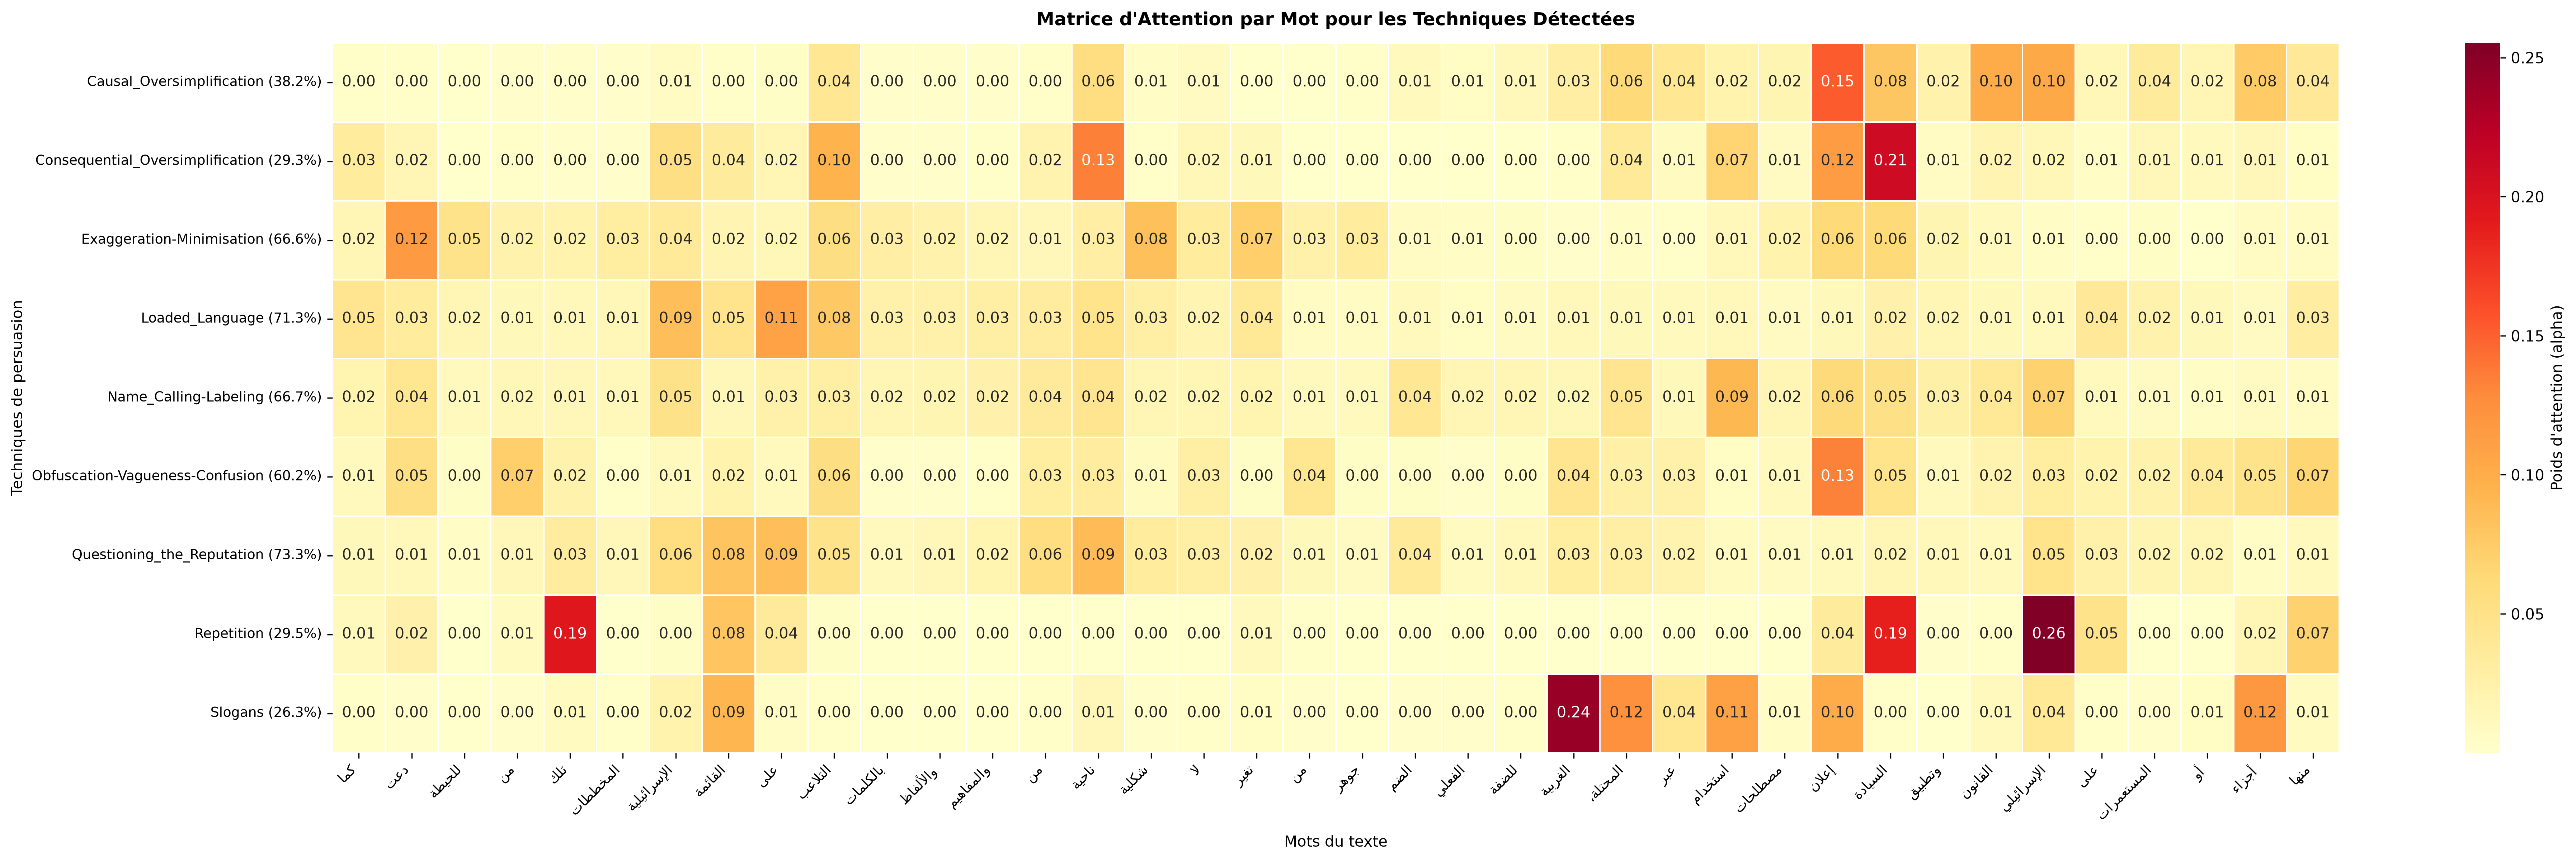

In [153]:
# =========================================================================
# ANALYSE ET VISUALISATION DE L'ATTENTION SUR LE JEU DE TEST (df_test)
# =========================================================================

# 1. Préparation du jeu de test (Tokenisation et regroupement si nécessaire)
if "tokens" not in df_test.columns:
    df_test["tokens"] = df_test["text"].apply(tokenize)
if "labels_grouped" not in df_test.columns and "labels" in df_test.columns:
    df_test["labels_grouped"] = df_test["labels"].apply(merge_rare_techniques)

def visualize_test_sample(sample_idx: int, save_heatmap: bool = True):
    """Visualise l'attention pour n'importe quel texte du jeu de Test."""
    sample_tokens = df_test["tokens"].iloc[sample_idx]
    vrais_labels = df_test["labels_grouped"].iloc[sample_idx] if "labels_grouped" in df_test.columns else df_test["labels"].iloc[sample_idx]

    print("=" * 75)
    print(f"📌 TEST SAMPLE #{sample_idx}")
    print("📝 Texte analysé :", " ".join(sample_tokens))
    print("🏷️ Vraies techniques annotées :", vrais_labels)
    print("=" * 75)

    # 1. Surlignage HTML interactif en arabe
    highlight_text_attention(
        model=model_attention,
        text_tokens=sample_tokens,
        class_names=class_names,
        device=device,
        threshold=0.20
    )

    # 2. Sauvegarde de la Heatmap dans le dossier Results
    if save_heatmap:
        save_img_path = f"c:/Users/user/Projets_Ghoufrane/LLMS/Decetction-Persuation/Results/attention_heatmap_test_sample_{sample_idx}.png"
        plot_attention_heatmap(
            model=model_attention,
            text_tokens=sample_tokens,
            class_names=class_names,
            device=device,
            threshold=0.20,
            save_path=save_img_path
        )

# -------------------------------------------------------------------------
# Exécution sur une sélection d'exemples de test riches en techniques
# (Indices 4, 12, 17, 22 couvrent Autorité, Doute, Exagération, Langage Chargé, etc.)
# -------------------------------------------------------------------------
test_indices_to_show = [4, 12, 17, 22]

for idx in test_indices_to_show:
    visualize_test_sample(sample_idx=idx, save_heatmap=True)
